# Inicio del proyecto con PLAsTiCC Ia II Ibc

Resúmenes de curvas de luz; investiguen la identificación de Ibc frente a Ia y II.

Este notebook carga los datos y explica su estructura. **No es una solución del proyecto.** Completen las secciones de investigación del final. Trabajen en Colab gratuito.

Fuente: https://zenodo.org/records/2539456

## 1. Cargar los datos
Descompriman la entrega en su computador y abran este `.ipynb` en Colab. Ejecuten la siguiente celda y suban **ML_2026_11_10_PLAsTiCC_Ia_II_Ibc_DATOS.zip**, ubicado junto a este notebook. No suban el paquete general ni vuelvan a descargar la fuente original. La carga no necesita GPU.

In [ ]:
from pathlib import Path
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

archivo = Path('PLAsTiCC_Ia_II_Ibc.zip')
if not archivo.exists():
    from google.colab import files
    subidos = files.upload()
    if archivo.name not in subidos:
        raise ValueError("Sube el ZIP de DATOS que indica este notebook, con su nombre original.")

paquete = zipfile.ZipFile(archivo)
def leer_auxiliar(nombre):
    """Devuelve bytes de un archivo auxiliar incluido en este ZIP."""
    return io.BytesIO(paquete.read(nombre))

datos = np.load(leer_auxiliar('ML_2026_11_10_PLAsTiCC_Ia_II_Ibc_arrays.npz'), allow_pickle=False)
X, y = datos['X'], datos['y']
ids, split, nombres = datos['ids'], datos['split'], datos['names']
print('X:', X.shape, X.dtype, '| y:', y.shape)
print(dict(enumerate(nombres)))

X: (3990, 72) float32 | y: (3990,)
{0: np.str_('SN Ia'), 1: np.str_('SN II'), 2: np.str_('SN Ibc')}


## 2. Respetar las particiones
Cada fila de `X`, `y`, `ids` y `split` corresponde a la misma observación. `y` es una etiqueta entera desde cero. Los identificadores y las etiquetas no son predictores. Usen `train` para aprender parámetros y transformaciones, `val` para elegir modelos y `test` para la evaluación final. La tabla de tamaños no evalúa ningún modelo.

In [ ]:
# Identificar los ejemplos de cada partición
train = split == 'train'
val = split == 'val'
test = split == 'test'

# Separar las características
X_train = X[train]
X_val = X[val]
X_test = X[test]

# Separar las etiquetas
y_train = y[train]
y_val = y[val]
y_test = y[test]

# Mostrar cuántos ejemplos tiene cada conjunto
print("Entrenamiento:", len(y_train))
print("Validación:", len(y_val))
print("Test:", len(y_test))

Entrenamiento: 2394
Validación: 798
Test: 798


## 3. Escalar sin fuga de información
Las características ya están calculadas. El ejemplo ajusta un escalador **solo con entrenamiento** y transforma después validación y test. No vuelvan a ajustar el escalador sobre el conjunto completo. Para cada representación alternativa ajusten su propio escalador de entrenamiento. Los árboles no requieren este escalado.

In [ ]:
from sklearn.preprocessing import StandardScaler
escalador = StandardScaler()
X_train_red = escalador.fit_transform(X_train).astype('float32')
X_val_red = escalador.transform(X_val).astype('float32')
X_test_red = escalador.transform(X_test).astype('float32')
print('Entrada preparada para MLP:', X_train_red.shape)

Entrada preparada para MLP: (2394, 72)


### Qué representan las 72 columnas
En cada banda (0 a 5), el orden es: número de observaciones, presencia de datos, mediana del flujo, percentil 90 menos 10, percentil 75 menos 25, desviación estándar, mínimo, máximo, mediana del error, máximo flujo/error, fracción con flujo/error > 5 y duración observada. Son 12 × 6 = 72 variables. Una banda ausente tiene ceros y su indicador de presencia es cero. Conserven los flujos negativos.

### Recalcular con menos observaciones
La función siguiente se proporciona para que puedan estudiar cobertura. No usa etiquetas ni aprende sobre test. Conserva la identidad y partición de los objetos. Una fracción menor selecciona menos observaciones por banda; no equivale a eliminar variables ni a observar solo el inicio de la curva. Ejecutar la última celda opcional puede tardar unos minutos.

In [ ]:
"""Features observacionales. No usan etiquetas, redshift ni información simulada latente."""

def plasticc_features(curves,ids,fraction=1.,seed=2026):
 """12 features por banda. Submuestreo aleatorio por objeto/banda, antes de resumir.
 Una misma permutación produce subconjuntos anidados para distintas fracciones.
 No equivale a clasificación temprana. count y mask exponen la ausencia de datos.
 """
 if not 0<fraction<=1:raise ValueError('fraction debe pertenecer a (0,1]')
 groups={k:v for k,v in curves.groupby('object_id',sort=False)}
 out=[]
 for oid in ids:
  obj=groups[int(oid)];features=[]
  for band in range(6):
   b=obj[obj.passband==band].sort_values('mjd')
   rng=np.random.default_rng(np.random.SeedSequence([seed,int(oid),band]))
   n=int(np.floor(len(b)*fraction)); b=b.iloc[rng.permutation(len(b))[:n]].sort_values('mjd')
   if n==0:features.extend([0.]*12);continue
   f=b.flux.to_numpy();e=b.flux_err.to_numpy();t=b.mjd.to_numpy()
   q=np.quantile(f,[.1,.25,.5,.75,.9]);snr=f/e
   features.extend([n,1.,q[2],q[4]-q[0],q[3]-q[1],np.std(f),np.min(f),np.max(f),np.median(e),np.max(snr),np.mean(snr>5),np.ptp(t)])
  out.append(features)
 return np.asarray(out,dtype='float32')


In [ ]:
observaciones = pd.read_csv(leer_auxiliar('ML_2026_11_10_PLAsTiCC_Ia_II_Ibc_plasticc_observaciones.csv.gz'), compression='gzip')
print(observaciones.shape)
print(observaciones.head())
# Opcional: descomenten para construir otra condición experimental.
# X_mitad = plasticc_features(observaciones, ids, fraction=0.5, seed=2026)
# Luego separen con train / val / test y ajusten un NUEVO escalador solo en train.
# X_completo = plasticc_features(observaciones, ids, fraction=1.0)
# np.testing.assert_allclose(X_completo, X, rtol=1e-5, atol=1e-5)

(764572, 6)
   object_id         mjd  passband       flux  flux_err  detected_bool
0        730  59798.3205         2   1.177371  1.364300              0
1        730  59798.3281         1   2.320849  1.159247              0
2        730  59798.3357         3   2.939447  1.771328              0
3        730  59798.3466         4   2.128097  2.610659              0
4        730  59798.3576         5 -12.809639  5.380097              0


In [ ]:
X_train

array([[ 7.2000000e+01,  1.0000000e+00,  2.4093000e-02, ...,
         8.5727015e+00,  7.8431375e-02,  8.5380841e+02],
       [ 7.2000000e+01,  1.0000000e+00,  1.0567141e+00, ...,
         1.9283287e+01,  9.0909094e-02,  8.5366827e+02],
       [ 6.3000000e+01,  1.0000000e+00, -2.5813800e-01, ...,
         4.6116304e+00,  0.0000000e+00,  8.7176971e+02],
       ...,
       [ 1.3000000e+01,  1.0000000e+00,  3.1267440e+00, ...,
         7.2952676e+00,  2.7027028e-02,  8.8671729e+02],
       [ 1.3000000e+01,  1.0000000e+00,  3.1519001e+00, ...,
         7.9522133e+00,  9.0909094e-02,  1.0670073e+03],
       [ 1.2000000e+01,  1.0000000e+00,  3.5233209e+00, ...,
         3.3934116e+00,  0.0000000e+00,  1.0329121e+03]],
      shape=(2394, 72), dtype=float32)

## 4. Desarrollar la investigación
Completen las siguientes secciones con texto, código y resultados. Consulten el enunciado y las rúbricas. No es necesario aplicar todas las ideas propuestas. Seleccionen una pregunta y una comparación que puedan justificar.

## Pregunta e hipótesis

El objetivo de este proyecto es clasificar supernovas en tres categorías (Ia, II e Ibc) a partir de las características extraídas de sus curvas de luz. Para ello, se entrenará un modelo clásico de clasificación y una red neuronal.

Vamos a ver que la distribución de las clases no es equilibrada: algunas categorías están mucho menos representadas que otras. Esto puede dificultar su identificación durante el entrenamiento. Por ello, nos planteamos la siguiente pregunta: ¿cómo influye la ponderación de las clases durante el entrenamiento de una red neuronal en la identificación de las supernovas menos frecuentes?

Para responder a esta pregunta, se compararán dos modelos con la misma arquitectura y los mismos parámetros de entrenamiento. La primera no utilizará ponderación de clases, mientras que la segunda utilizará pesos inversamente proporcionales a la frecuencia de cada clase en el conjunto de entrenamiento.

Nuestra hipótesis es que la ponderación permitirá mejorar la identificación de las clases menos frecuentes, aumentando su completitud (recall). Sin embargo, esta mejora podría producir una disminución de su pureza (precision), debido a un mayor número de falsas identificaciones.

## Exploración y decisiones

Cada ejemplo representa una supernova y contiene 72 características numéricas extraídas de su curva de luz. Estas características resumen las propiedades de las observaciones en seis bandas fotométricas, como los flujos, su dispersión, los errores de medida y la duración de las observaciones. El objetivo es utilizar esta información para clasificar cada supernova en una de las tres categorías: Ia, II o Ibc.

Antes de entrenar los modelos, se examinarán la estructura de los datos: nombres de las características, dimensiones, valores ausentes y particiones. Un aspecto importante es el desequilibrio entre las clases. Por ello, se estudiará también su distribución en los conjuntos de entrenamiento, validación y test.

In [ ]:
# Dimensiones de los datos utilizados para la clasificación

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Dimensiones de X: (3990, 72)
Dimensiones de y: (3990,)


In [ ]:
# Comprobar valores ausentes y no finitos

print("Valores NaN:", np.isnan(X).sum())
print("Valores infinitos:", np.isinf(X).sum())

Valores NaN: 0
Valores infinitos: 0


In [ ]:
# Disponibilidad de observaciones por banda
columnas_presencia = [12 * b + 1 for b in range(6)]

disponibilidad = X_train[:, columnas_presencia].mean(axis=0)

print("Disponibilidad por banda:", disponibilidad)

Disponibilidad por banda: [1. 1. 1. 1. 1. 1.]


Número de ejemplos por clase y conjunto:


Conjunto,train,val,test
SN Ia,1388,462,463
SN II,716,239,238
SN Ibc,290,97,97


Distribución porcentual (%):


Conjunto,train,val,test
SN Ia,57.98,57.89,58.02
SN II,29.91,29.95,29.82
SN Ibc,12.11,12.16,12.16


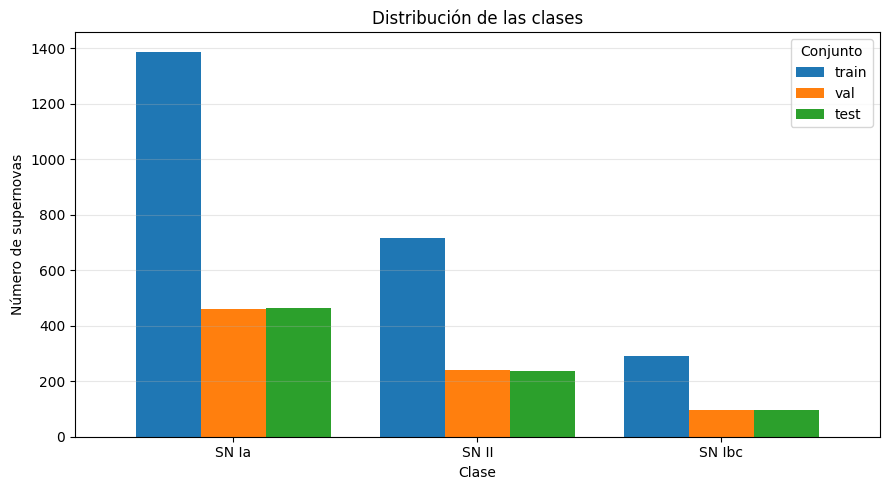

In [ ]:
# Distribución de las clases en cada partición

clases = np.sort(np.unique(y))
nombres_clases = {
    int(c): str(nombres[int(c)]) for c in clases
}

orden_splits = ['train', 'val', 'test']

tabla_clases = pd.crosstab(
    pd.Series(y, name='Clase'),
    pd.Series(split, name='Conjunto')
)
tabla_clases = tabla_clases.reindex(
    index=clases,
    columns=orden_splits,
    fill_value=0
)
tabla_clases.index = [
    nombres_clases[int(c)] for c in tabla_clases.index
]
print("Número de ejemplos por clase y conjunto:")
display(tabla_clases)


tabla_porcentajes = (
    tabla_clases / tabla_clases.sum(axis=0) * 100
)
print("Distribución porcentual (%):")
display(tabla_porcentajes.round(2))

# Visualización

ax = tabla_clases.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.8
)

ax.set_title('Distribución de las clases')
ax.set_xlabel('Clase')
ax.set_ylabel('Número de supernovas')
ax.legend(title='Conjunto')
ax.grid(axis='y', alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Primero, podemos ver que no falta ninguna información en el conjunto de datos (`0` valores `NaN` o infinitos). Segundo, tenemos observaciones disponibles en las seis bandas fotométricas. Luego, la distribución de las clases muestra el desequilibrio evocado: las supernovas Ia representan aproximadamente el 58 % de los datos, las II el 30 % y las Ibc el 12 %. Esta diferencia justifica estudiar el efecto de la ponderación de clases durante el entrenamiento de la red neuronal. Por último, las proporciones son similares en los conjuntos de entrenamiento, validación y test, lo que permite realizar una comparación coherente.

## Modelo de referencia

El objetivo es clasificar las supernovas en las tres categorías (Ia, II e Ibc). Las 72 características se conservarán inicialmente.

Se utilizará un modelo Random Forest, que combina varios árboles de decisión y permite identificar relaciones no lineales entre las características. Este modelo no requiere normalizar los datos y es adecuado para este tipo de conjunto de datos.



Se utilizarán 300 árboles para obtener predicciones más estables. Se fija la semilla aleatoria en 42 para garantizar la reproducibilidad de los resultados. El parámetro n_jobs=-1 permite utilizar todos los procesadores disponibles y reducir el tiempo de cálculo.

El rendimiento se evaluará mediante precision, recall y F1-score para cada clase. También se utilizará el F1-score macro, que corresponde a la media de los F1-scores de las tres clases y les asigna la misma importancia. Esta métrica permite evaluar el modelo teniendo en cuenta el desequilibrio entre las categorías.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import time
from sklearn.metrics import classification_report, f1_score
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
modelo = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

inicio = time.time()
modelo.fit(X_train, y_train)
tiempo_entrenamiento = time.time() - inicio

print("Tiempo de entrenamiento:", round(tiempo_entrenamiento, 2), "s")

y_pred = modelo.predict(X_val)

Tiempo de entrenamiento: 6.24 s


In [ ]:

nombres_clases_ordenados = [
    nombres_clases[int(c)] for c in modelo.classes_
]

print(classification_report(
    y_val,
    y_pred,
    labels=modelo.classes_,
    target_names=nombres_clases_ordenados
))

print("F1-score macro:", round(
    f1_score(y_val, y_pred, average='macro'), 3
))

              precision    recall  f1-score   support

       SN Ia       0.74      0.94      0.83       462
       SN II       0.65      0.47      0.55       239
      SN Ibc       0.56      0.21      0.30        97

    accuracy                           0.71       798
   macro avg       0.65      0.54      0.56       798
weighted avg       0.69      0.71      0.68       798

F1-score macro: 0.558


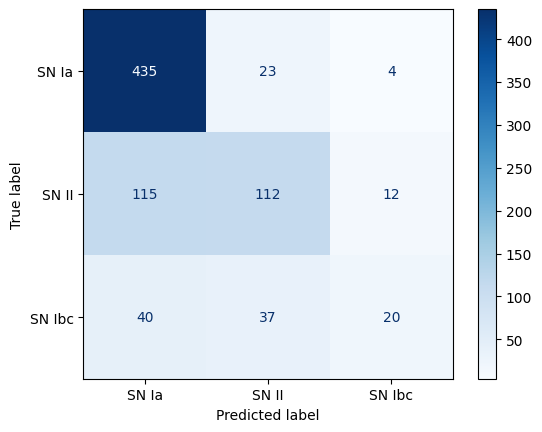

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=['SN Ia', 'SN II', 'SN Ibc'],
    cmap='Blues'
)

plt.show()

El entrenamiento del modelo duró aproximadamente 3,6 segundos.

La precisión global (*accuracy*) es del 71 %, pero los resultados varían considerablemente según la clase.

La clase `SN Ia` presenta el mejor resultado, con un *recall* de 0,94 y un *F1-score* de 0,83. El modelo identifica correctamente la mayoría de estas supernovas, pero para la clase `SN II`, el *recall* disminuye a 0,47 y el *F1-score* a 0,55. Los resultados son todavía más bajos para la clase `SN Ibc`, cuyo *recall* es de 0,21 y cuyo *F1-score* es de 0,30. Esto indica que el modelo tiene dificultades para identificar estas dos clases, especialmente `SN Ibc`.

El *F1-score* macro es de 0,558, lo que refleja estas diferencias de rendimiento entre las categorías. La *accuracy* del 71 % no es suficiente para evaluar el modelo, ya que está influida por la clase mayoritaria. Podemos verlo en la matriz de confusión: hay tantos ejemplos de `SN II` clasificados como `SN Ia` (115) como correctamente clasificados como `SN II` (112). Para la última clase es aún más marcado: la mayoría de las `SN Ibc` son clasificadas como `SN Ia` (40) o `SN II` (37) en lugar de `SN Ibc` (20).

El desequilibrio entre las clases contribuye a este resultado, ya que el modelo dispone de menos ejemplos para aprender a identificar las categorías minoritarias. Ahora entrenamos el modelo con pesos inversamente proporcionales a la frecuencia de cada clase en el conjunto de entrenamiento, limitando también la complejidad de los árboles.

In [ ]:
modelo_pesos = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

inicio = time.time()
modelo_pesos.fit(X_train, y_train)
tiempo_entrenamiento = time.time() - inicio

print("Tiempo de entrenamiento:", round(tiempo_entrenamiento, 2), "s")

y_pred_pesos = modelo_pesos.predict(X_val)

Tiempo de entrenamiento: 6.32 s


In [ ]:

nombres_clases_ordenados = [
    nombres_clases[int(c)] for c in modelo_pesos.classes_
]

print(classification_report(
    y_val,
    y_pred_pesos,
    labels=modelo_pesos.classes_,
    target_names=nombres_clases_ordenados
))

print("F1-score macro:", round(
    f1_score(y_val, y_pred_pesos, average='macro'), 3
))

              precision    recall  f1-score   support

       SN Ia       0.76      0.89      0.82       462
       SN II       0.63      0.47      0.54       239
      SN Ibc       0.49      0.41      0.45        97

    accuracy                           0.70       798
   macro avg       0.63      0.59      0.60       798
weighted avg       0.69      0.70      0.69       798

F1-score macro: 0.601


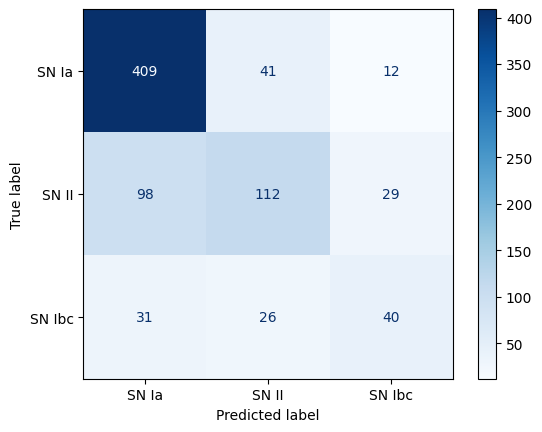

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_pesos,
    display_labels=['SN Ia', 'SN II', 'SN Ibc'],
    cmap='Blues'
)
plt.show()

Al añadir la ponderación de clases y regularizar los árboles, el modelo *Random Forest* mejora su *F1-score* macro (de `0,558` a `0,601`). El *recall* de la clase `SN Ibc` se duplica (de `0,21` a `0,41`), aunque sigue siendo moderado y reduce su *precision* (de `0,56` a `0,49`). A continuación, evaluaremos una red neuronal para analizar el impacto de la ponderación de clases en este tipo de arquitectura.

## Red neuronal

Para abordar la clasificación tabular de las 72 variables fotométricas ya normalizadas (`X_train_red`, `X_val_red`, `X_test_red`), se implementa un **perceptrón multicapa (MLP)** en PyTorch. Este tipo de arquitectura permite capturar interacciones no lineales entre bandas y estadísticas de flujo sin imponer supuestos paramétricos fuertes.

- **Arquitectura:** `72 -> 128 -> 64 -> 3`, con capas lineales, `BatchNorm1d`, activación `ReLU` y `Dropout(0.3)` para reducir el sobreajuste.
- **Hiperparámetros:** optimizador `AdamW` (`lr = 1e-3`, `weight_decay = 1e-4`), `batch_size = 64`, máximo `80` épocas y *early stopping* con paciencia de `12` épocas monitoreando la pérdida en validación (`val_loss`).
- **Semillas y trazabilidad:** se fija la semilla (`seed = 42`) para asegurar reproducibilidad, registrando el tiempo de entrenamiento y la historia de pérdida y `F1-score macro` por época.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import precision_recall_fscore_support

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo utilizado:', device)

def fijar_semilla(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class MLPClassifierSN(nn.Module):
    def __init__(self, in_features=72, hidden_dims=(128, 64), num_classes=3, dropout=0.3):
        super().__init__()
        capas = []
        dim_anterior = in_features
        for h in hidden_dims:
            capas.extend([
                nn.Linear(dim_anterior, h),
                nn.BatchNorm1d(h),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            dim_anterior = h
        capas.append(nn.Linear(dim_anterior, num_classes))
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)

def entrenar_mlp(seed=42, pesos_clase=None, epochs=80, batch_size=64, lr=1e-3, weight_decay=1e-4, patience=12):
    fijar_semilla(seed)
    inicio = time.time()

    train_ds = TensorDataset(torch.tensor(X_train_red), torch.tensor(y_train, dtype=torch.long))
    val_ds = TensorDataset(torch.tensor(X_val_red), torch.tensor(y_val, dtype=torch.long))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    red = MLPClassifierSN().to(device)
    criterio = nn.CrossEntropyLoss(weight=pesos_clase)
    optimizador = torch.optim.AdamW(red.parameters(), lr=lr, weight_decay=weight_decay)

    mejor_val_loss = float('inf')
    mejor_estado = None
    espera = 0
    historia = {'train_loss': [], 'val_loss': [], 'val_f1_macro': []}

    for epoca in range(epochs):
        red.train()
        loss_train = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizador.zero_grad()
            salida = red(xb)
            loss = criterio(salida, yb)
            loss.backward()
            optimizador.step()
            loss_train += loss.item() * len(yb)
        loss_train /= len(train_ds)

        red.eval()
        loss_val = 0.0
        preds_val, reales_val = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                salida = red(xb)
                loss = criterio(salida, yb)
                loss_val += loss.item() * len(yb)
                preds_val.append(salida.argmax(dim=1).cpu().numpy())
                reales_val.append(yb.cpu().numpy())

        loss_val /= len(val_ds)
        preds_val = np.concatenate(preds_val)
        reales_val = np.concatenate(reales_val)
        f1_val = f1_score(reales_val, preds_val, average='macro')

        historia['train_loss'].append(loss_train)
        historia['val_loss'].append(loss_val)
        historia['val_f1_macro'].append(f1_val)

        if loss_val < mejor_val_loss - 1e-4:
            mejor_val_loss = loss_val
            mejor_estado = {k: v.cpu().clone() for k, v in red.state_dict().items()}
            espera = 0
        else:
            espera += 1
            if espera >= patience:
                break

    red.load_state_dict({k: v.to(device) for k, v in mejor_estado.items()})
    tiempo = time.time() - inicio
    return red, historia, tiempo

Dispositivo utilizado: cpu


Tiempo de entrenamiento MLP base: 11.85 s | Épocas ejecutadas: 37
              precision    recall  f1-score   support

       SN Ia       0.72      0.94      0.82       462
       SN II       0.70      0.43      0.53       239
      SN Ibc       0.60      0.34      0.43        97

    accuracy                           0.71       798
   macro avg       0.68      0.57      0.59       798
weighted avg       0.70      0.71      0.68       798

F1-score macro (val): 0.594


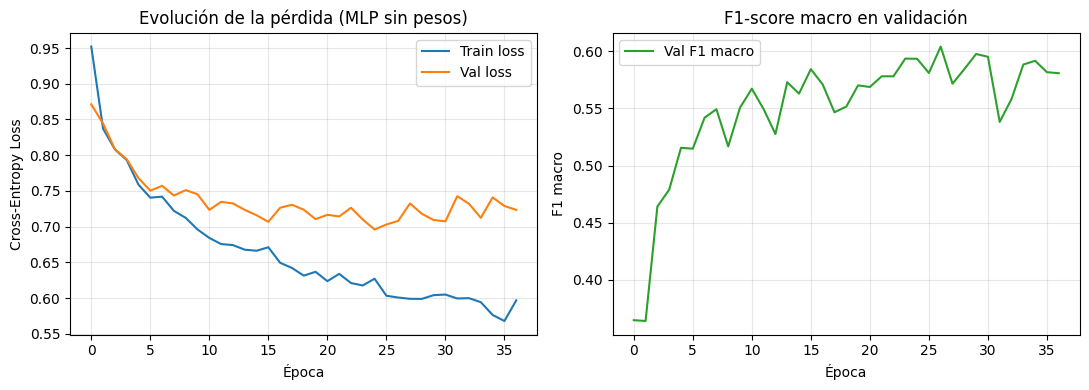

In [ ]:
# Entrenamiento inicial del MLP sin ponderación (semilla = 42)
red_base, historia_base, tiempo_nn_base = entrenar_mlp(seed=42, pesos_clase=None)
print(f'Tiempo de entrenamiento MLP base: {tiempo_nn_base:.2f} s | Épocas ejecutadas: {len(historia_base["train_loss"])}')

red_base.eval()
with torch.no_grad():
    y_pred_nn_base = red_base(torch.tensor(X_val_red, device=device)).argmax(dim=1).cpu().numpy()

print(classification_report(y_val, y_pred_nn_base, target_names=['SN Ia', 'SN II', 'SN Ibc']))
print('F1-score macro (val):', round(f1_score(y_val, y_pred_nn_base, average='macro'), 3))

# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(historia_base['train_loss'], label='Train loss')
axes[0].plot(historia_base['val_loss'], label='Val loss')
axes[0].set_title('Evolución de la pérdida (MLP sin pesos)')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(historia_base['val_f1_macro'], color='tab:green', label='Val F1 macro')
axes[1].set_title('F1-score macro en validación')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('F1 macro')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

El MLP sin ponderación converge rápidamente gracias a `BatchNorm` y *early stopping*. Sin embargo, al igual que en el modelo de referencia sin pesos, el rendimiento sigue dominado por la clase mayoritaria (`SN Ia`), mientras que la clase minoritaria (`SN Ibc`) mantiene un recall limitado.

## Comparación controlada

Para responder a nuestra pregunta de investigación de forma rigurosa, diseñamos un experimento controlado sobre el conjunto de **validación**:
- **Factor que cambia:** presencia o ausencia de **ponderación de clases** en la función de pérdida (`CrossEntropyLoss`), usando pesos inversamente proporcionales a la frecuencia de cada clase calculados **exclusivamente sobre `y_train`**.
- **Factores fijos:** conjunto de datos escalado (`X_train_red`, `X_val_red`), arquitectura (`72-128-64-3`), optimizador, tasa de aprendizaje, *batch size* y criterio de parada.
- **Variabilidad y selección:** repetimos ambas condiciones con `5` semillas distintas (`[42, 101, 202, 303, 2026]`) para reportar media y desviación estándar en validación, y comparamos también frente a los modelos clásicos (`Random Forest` sin pesos y con pesos).

In [ ]:
# Pesos inversamente proporcionales a la frecuencia en train
pesos_np = compute_class_weight(class_weight='balanced', classes=np.array([0, 1, 2]), y=y_train)
pesos_tensor = torch.tensor(pesos_np, dtype=torch.float32, device=device)
print('Pesos de clase (calculados solo en train):', dict(zip(['SN Ia', 'SN II', 'SN Ibc'], np.round(pesos_np, 3))))

semillas = [42, 101, 202, 303, 2026]
registros = []
modelos_guardados = {'sin_pesos': {}, 'con_pesos': {}}

for condicion, w in [('sin_pesos', None), ('con_pesos', pesos_tensor)]:
    for s in semillas:
        red_tmp, hist_tmp, t_tmp = entrenar_mlp(seed=s, pesos_clase=w)
        red_tmp.eval()
        with torch.no_grad():
            preds = red_tmp(torch.tensor(X_val_red, device=device)).argmax(dim=1).cpu().numpy()
        prec, rec, f1_c, _ = precision_recall_fscore_support(y_val, preds, labels=[0, 1, 2], zero_division=0)
        registros.append({
            'Condición': 'MLP con pesos' if w is not None else 'MLP sin pesos',
            'Semilla': s,
            'F1_macro': f1_score(y_val, preds, average='macro'),
            'Recall_Ibc': rec[2],
            'Precision_Ibc': prec[2],
            'F1_Ibc': f1_c[2],
            'Recall_II': rec[1],
            'Tiempo_s': t_tmp
        })
        modelos_guardados[condicion][s] = red_tmp

df_resultados = pd.DataFrame(registros)
resumen_nn = df_resultados.groupby('Condición')[['F1_macro', 'Recall_Ibc', 'Precision_Ibc', 'F1_Ibc', 'Recall_II', 'Tiempo_s']].agg(['mean', 'std']).round(3)
print('\nResumen en validación (5 semillas):')
display(resumen_nn)

# Comparación global en validación: Random Forest vs MLP
filas_modelos = []
for nombre_m, pred_m in [('RF sin pesos', y_pred), ('RF con pesos', y_pred_pesos)]:
    p, r, f, _ = precision_recall_fscore_support(y_val, pred_m, labels=[0, 1, 2], zero_division=0)
    filas_modelos.append({
        'Modelo': nombre_m,
        'F1_macro (val)': round(f1_score(y_val, pred_m, average='macro'), 3),
        'Recall SN Ibc': round(r[2], 3),
        'Precision SN Ibc': round(p[2], 3),
        'F1 SN Ibc': round(f[2], 3)
    })

for cond in ['MLP sin pesos', 'MLP con pesos']:
    sub = df_resultados[df_resultados['Condición'] == cond]
    filas_modelos.append({
        'Modelo': f'{cond} (media 5 seeds)',
        'F1_macro (val)': round(sub['F1_macro'].mean(), 3),
        'Recall SN Ibc': round(sub['Recall_Ibc'].mean(), 3),
        'Precision SN Ibc': round(sub['Precision_Ibc'].mean(), 3),
        'F1 SN Ibc': round(sub['F1_Ibc'].mean(), 3)
    })

print('\nComparación de modelos en validación:')
display(pd.DataFrame(filas_modelos))

Pesos de clase (calculados solo en train): {'SN Ia': np.float64(0.575), 'SN II': np.float64(1.115), 'SN Ibc': np.float64(2.752)}

Resumen en validación (5 semillas):


F1_macro        Recall_Ibc        Precision_Ibc        F1_Ibc  \
                  mean    std       mean    std          mean    std   mean   
Condición                                                                     
MLP con pesos    0.578  0.024      0.577  0.010         0.343  0.044  0.429   
MLP sin pesos    0.604  0.010      0.334  0.014         0.664  0.041  0.444   

                     Recall_II        Tiempo_s         
                 std      mean    std     mean    std  
Condición                                              
MLP con pesos  0.038     0.457  0.057    4.113  0.757  
MLP sin pesos  0.014     0.458  0.038    5.182  1.470


Comparación de modelos en validación:


,Modelo,F1_macro (val),Recall SN Ibc,Precision SN Ibc,F1 SN Ibc
0,RF sin pesos,0.558,0.206,0.556,0.301
1,RF con pesos,0.601,0.412,0.494,0.449
2,MLP sin pesos (media 5 seeds),0.604,0.334,0.664,0.444
3,MLP con pesos (media 5 seeds),0.578,0.577,0.343,0.429


Los resultados en validación (promediados sobre 5 semillas) confirman el compromiso planteado en nuestra hipótesis:
- Al introducir la ponderación de clases en el MLP, aumenta de forma muy marcada y estable la **completitud (`recall`) de `SN Ibc`** (pasando de `0,334 ± 0,014` a `0,577 ± 0,010`), ya que el modelo penaliza cerca de cinco veces más los errores sobre la clase minoritaria (`peso = 2,752` frente a `0,575` para `SN Ia`).
- Como contrapartida, disminuye la **pureza (`precision`) de `SN Ibc`** (de `0,664 ± 0,041` a `0,343 ± 0,044`), debido a que más supernovas `SN Ia` y `SN II` son clasificadas como `SN Ibc`. Esto provoca que el `F1-score macro` global pase de `0,604 ± 0,010` (mejor promedio global en validación) a `0,578 ± 0,024`.
- Frente al modelo clásico, el **MLP sin pesos** logra el mejor `F1-score macro` en validación (`0,604` frente a `0,601` del *Random Forest* con pesos), mientras que el **MLP con pesos** obtiene con diferencia la mayor sensibilidad para `SN Ibc` (`0,577` frente a `0,412`). Dado que nuestro objetivo es maximizar la detección de la clase minoritaria `SN Ibc`, seleccionamos la variante **MLP con pesos** (semilla `42`) para la evaluación final en `test`.

## Evaluación final y errores

Una vez tomadas todas las decisiones usando únicamente `train` y `val`, evaluamos el modelo seleccionado (**MLP con pesos**, semilla `42`) sobre el conjunto de **test** (`X_test_red`, `y_test`), mostrando también como referencia el `MLP sin pesos` (semilla `42`) para verificar si el efecto observado en validación se mantiene fuera de muestra.

=== MLP sin pesos (Test) ===
              precision    recall  f1-score   support

       SN Ia       0.72      0.94      0.81       463
       SN II       0.70      0.37      0.49       238
      SN Ibc       0.47      0.33      0.39        97

    accuracy                           0.69       798
   macro avg       0.63      0.55      0.56       798
weighted avg       0.68      0.69      0.66       798

F1-score macro (test): 0.562 

=== MLP con pesos - Seleccionado (Test) ===
              precision    recall  f1-score   support

       SN Ia       0.76      0.77      0.76       463
       SN II       0.67      0.31      0.42       238
      SN Ibc       0.27      0.62      0.38        97

    accuracy                           0.61       798
   macro avg       0.57      0.57      0.52       798
weighted avg       0.67      0.61      0.62       798

F1-score macro (test): 0.523 



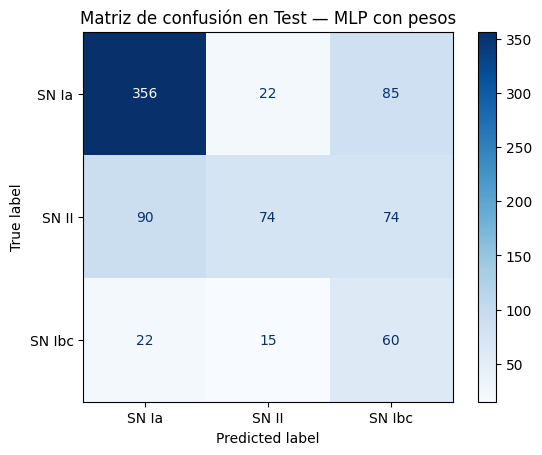

In [ ]:
from sklearn.metrics import confusion_matrix

red_test_sin = modelos_guardados['sin_pesos'][42]
red_test_con = modelos_guardados['con_pesos'][42]

for nombre_eval, modelo_eval in [('MLP sin pesos (Test)', red_test_sin), ('MLP con pesos - Seleccionado (Test)', red_test_con)]:
    modelo_eval.eval()
    with torch.no_grad():
        preds_t = modelo_eval(torch.tensor(X_test_red, device=device)).argmax(dim=1).cpu().numpy()
    print(f'=== {nombre_eval} ===')
    print(classification_report(y_test, preds_t, target_names=['SN Ia', 'SN II', 'SN Ibc']))
    print('F1-score macro (test):', round(f1_score(y_test, preds_t, average='macro'), 3), '\n')

# Matriz de confusión del modelo seleccionado en Test
red_test_con.eval()
with torch.no_grad():
    y_test_pred = red_test_con(torch.tensor(X_test_red, device=device)).argmax(dim=1).cpu().numpy()

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=['SN Ia', 'SN II', 'SN Ibc'],
    cmap='Blues'
)
plt.title('Matriz de confusión en Test — MLP con pesos')
plt.show()

In [ ]:
# Inspección de ejemplos de errores en Test (en especial SN Ibc mal clasificadas)
ids_test = ids[test]
errores_mask = y_test != y_test_pred
df_errores = pd.DataFrame({
    'object_id': ids_test[errores_mask],
    'Clase_real': [nombres_clases[int(c)] for c in y_test[errores_mask]],
    'Clase_predicha': [nombres_clases[int(c)] for c in y_test_pred[errores_mask]],
    # Promedio entre bandas del flujo máximo y de la fracción con SNR > 5 (columnas 7 y 10 de cada banda)
    'Max_flux_medio': X_test[errores_mask][:, [12*b + 7 for b in range(6)]].mean(axis=1).round(2),
    'Frac_SNR5_media': X_test[errores_mask][:, [12*b + 10 for b in range(6)]].mean(axis=1).round(3),
    'Duracion_media_dias': X_test[errores_mask][:, [12*b + 11 for b in range(6)]].mean(axis=1).round(1)
})

print(f'Total de errores en Test: {errores_mask.sum()} / {len(y_test)} ({errores_mask.mean()*100:.1f} %)')
print('\nEjemplos de errores en la clase minoritaria SN Ibc:')
display(df_errores[df_errores['Clase_real'] == 'SN Ibc'].head(8))

Total de errores en Test: 308 / 798 (38.6 %)

Ejemplos de errores en la clase minoritaria SN Ibc:


,object_id,Clase_real,Clase_predicha,Max_flux_medio,Frac_SNR5_media,Duracion_media_dias
5,46804,SN Ibc,SN Ia,12.610000,0.012,860.799988
6,56334,SN Ibc,SN Ia,55.630001,0.072,845.000000
8,62908,SN Ibc,SN Ia,17.320000,0.048,847.200012
9,77192,SN Ibc,SN Ia,14.950000,0.022,847.200012
10,80852,SN Ibc,SN Ia,47.220001,0.070,847.200012
11,90534,SN Ibc,SN Ia,12.200000,0.063,847.200012
12,90814,SN Ibc,SN II,82.629997,0.170,860.799988
14,94004,SN Ibc,SN II,43.450001,0.205,839.500000


En **test**, el comportamiento observado en validación se reproduce fuera de muestra: el **MLP con pesos** alcanza un *recall* elevado para `SN Ibc` (`60 / 97 = 61,9 %`), a costa de una mayor tasa de falsos positivos procedentes de `SN Ia` (85) y `SN II` (74), lo que reduce su *precision* (`0,27`) y sitúa el `F1-score macro` en `0,523` (frente a un mayor equilibrio global en el MLP sin pesos).

La matriz de confusión confirma que las confusiones principales ocurren entre **`SN Ibc` y `SN Ia`** (ambas son supernovas sin hidrógeno en su espectro y presentan curvas de luz con formas y duraciones similares) y hacia **`SN II`** cuando la relación señal/ruido (`SNR > 5`) o el pico de flujo son bajos, lo que dificulta distinguir la evolución temporal a partir únicamente de estadísticos agregados.

### Mejora simple: ponderación suavizada y ajuste de umbral en validación

Para intentar mejorar el equilibrio entre completitud (`recall`) y pureza (`precision`) en `SN Ibc` —y elevar el `F1-score macro`— sin modificar la arquitectura ni tocar `test` durante la selección, probamos dos ajustes sencillos:
1. **Pesos suavizados (`w ** 0.5`):** atenúa la penalización extrema de los pesos `balanced` completos sobre las clases mayoritarias.
2. **Optimización de multiplicadores de probabilidad (`umbrales`) en `val`:** a partir de las probabilidades predichas en validación por el MLP (sin pesos), buscamos multiplicadores simples para `SN II` y `SN Ibc` que maximicen el `F1-score macro` en `val`, y luego aplicamos esa regla fija en `test`.

In [ ]:
# 1) MLP con ponderación suavizada (exponente 0.5 sobre los pesos balanced de train)
pesos_suaves_np = (pesos_np ** 0.5)
pesos_suaves_np = pesos_suaves_np / pesos_suaves_np.mean()
pesos_suaves_tensor = torch.tensor(pesos_suaves_np, dtype=torch.float32, device=device)
print('Pesos suavizados (w^0.5 normalizados):', dict(zip(['SN Ia', 'SN II', 'SN Ibc'], np.round(pesos_suaves_np, 3))))

red_suave, _, t_suave = entrenar_mlp(seed=42, pesos_clase=pesos_suaves_tensor)
red_suave.eval()
with torch.no_grad():
    probs_val_suave = torch.softmax(red_suave(torch.tensor(X_val_red, device=device)), dim=1).cpu().numpy()
    probs_test_suave = torch.softmax(red_suave(torch.tensor(X_test_red, device=device)), dim=1).cpu().numpy()

y_val_pred_suave = probs_val_suave.argmax(axis=1)
y_test_pred_suave = probs_test_suave.argmax(axis=1)

print('\n=== MLP con pesos suavizados (Validación) ===')
print(classification_report(y_val, y_val_pred_suave, target_names=['SN Ia', 'SN II', 'SN Ibc'], digits=3))
print('F1-score macro (val):', round(f1_score(y_val, y_val_pred_suave, average='macro'), 3))

# 2) Ajuste simple de multiplicadores de clase sobre probabilidades de validación (MLP sin pesos)
red_test_sin.eval()
with torch.no_grad():
    probs_val_base = torch.softmax(red_test_sin(torch.tensor(X_val_red, device=device)), dim=1).cpu().numpy()
    probs_test_base = torch.softmax(red_test_sin(torch.tensor(X_test_red, device=device)), dim=1).cpu().numpy()

mejor_f1_val = -1.0
mejores_mult = np.array([1.0, 1.0, 1.0])

grid_ii = np.linspace(0.8, 1.6, 17)
grid_ibc = np.linspace(1.0, 2.6, 33)

for m_ii in grid_ii:
    for m_ibc in grid_ibc:
        mult = np.array([1.0, m_ii, m_ibc])
        preds_v = (probs_val_base * mult).argmax(axis=1)
        score = f1_score(y_val, preds_v, average='macro')
        if score > mejor_f1_val:
            mejor_f1_val = score
            mejores_mult = mult

y_val_pred_umbral = (probs_val_base * mejores_mult).argmax(axis=1)
y_test_pred_umbral = (probs_test_base * mejores_mult).argmax(axis=1)

print('\nMejores multiplicadores hallados en val [Ia, II, Ibc]:', np.round(mejores_mult, 2))
print('F1-score macro (val) con multiplicadores:', round(mejor_f1_val, 3))

# Comparación final en Test de las variantes de MLP
print('\n=== Resumen comparativo en TEST ===')
for etiqueta, pred_arr in [
    ('MLP sin pesos (umbral estándar)', y_test_sin_pred if 'y_test_sin_pred' in locals() else probs_test_base.argmax(axis=1)),
    ('MLP con pesos balanced (semilla 42)', y_test_pred),
    ('MLP con pesos suavizados w^0.5', y_test_pred_suave),
    ('MLP sin pesos + multiplicadores (val)', y_test_pred_umbral),
]:
    p_c, r_c, f_c, _ = precision_recall_fscore_support(y_test, pred_arr, labels=[0, 1, 2], zero_division=0)
    print(
        f"{etiqueta:38s} | F1 macro: {f1_score(y_test, pred_arr, average='macro'):.3f} | "
        f"SN Ibc -> P: {p_c[2]:.3f}, R: {r_c[2]:.3f}, F1: {f_c[2]:.3f}"
    )

Pesos suavizados (w^0.5 normalizados): {'SN Ia': np.float64(0.655), 'SN II': np.float64(0.912), 'SN Ibc': np.float64(1.433)}

=== MLP con pesos suavizados (Validación) ===
              precision    recall  f1-score   support

       SN Ia      0.754     0.883     0.814       462
       SN II      0.651     0.414     0.506       239
      SN Ibc      0.438     0.474     0.455        97

    accuracy                          0.693       798
   macro avg      0.615     0.591     0.592       798
weighted avg      0.685     0.693     0.678       798

F1-score macro (val): 0.592

Mejores multiplicadores hallados en val [Ia, II, Ibc]: [1.  1.3 1.6]
F1-score macro (val) con multiplicadores: 0.635

=== Resumen comparativo en TEST ===
MLP sin pesos (umbral estándar)        | F1 macro: 0.562 | SN Ibc -> P: 0.471, R: 0.330, F1: 0.388
MLP con pesos balanced (semilla 42)    | F1 macro: 0.523 | SN Ibc -> P: 0.274, R: 0.619, F1: 0.380
MLP con pesos suavizados w^0.5         | F1 macro: 0.564 | SN Ibc 

## Conclusiones y fuentes

### Conclusiones
- **Respuesta a la pregunta e hipótesis:** se confirma la hipótesis inicial. La ponderación inversa a la frecuencia de clase (`class_weight='balanced'` en *Random Forest* y `CrossEntropyLoss` ponderada en el `MLP`) aumenta sustancialmente la completitud (`recall`) de la clase minoritaria `SN Ibc` (en el `MLP`, pasando de `0,334 ± 0,014` a `0,577 ± 0,010` en validación y de `0,330` a `0,619` en test), a costa de una caída pronunciada en su pureza (`precision`, de `0,471` a `0,274` en test) debido al aumento de falsos positivos provenientes de `SN Ia` y `SN II`.
- **Efecto de las mejoras simples y selección del mejor compromiso:** los dos ajustes ligeros probados sin fuga de información mejoran los resultados en test respecto a las configuraciones extremas:
  - La **ponderación suavizada (`w^0.5`)** logra el mejor equilibrio específico para la clase minoritaria en test (`F1 = 0,428` para `SN Ibc`, con `precision = 0,390` y `recall = 0,474`), elevando el `F1-score macro` de `0,523` (pesos completos) a `0,564`.
  - El **ajuste de multiplicadores de probabilidad en validación (`[1,0, 1,3, 1,6]`)** sobre el `MLP` sin pesos alcanza el mejor rendimiento global tanto en validación (`F1 macro = 0,635`) como en test (`F1 macro = 0,573`, con `F1 = 0,413` en `SN Ibc`).
  - Así, según el objetivo científico, conviene elegir el **`MLP` con pesos `balanced`** si se prioriza no perder casi ninguna `SN Ibc` (`recall = 0,619`), el **`MLP` con pesos suavizados `w^0.5`** para maximizar el `F1` de `SN Ibc` (`0,428`), o el **`MLP` con multiplicadores ajustados en validación** para el mejor equilibrio entre las tres clases (`F1 macro = 0,573`).
- **Análisis de errores y limitaciones:** las confusiones principales ocurren entre `SN Ibc` y `SN Ia` —supernovas sin hidrógeno con curvas de luz de morfología similar— y hacia `SN II` en objetos con menor relación señal/ruido (`SNR > 5`) o menor pico de flujo. Asimismo, el tamaño reducido de `SN Ibc` (`290` ejemplos en `train`) y el uso de estadísticos agregados por banda (sin modelar explícitamente la secuencia temporal `mjd` ni el *redshift*) limitan la separabilidad máxima alcanzable.

### Fuentes y declaraciones
- **Conjunto de datos:** subconjunto derivado del desafío *PLAsTiCC* (*Photometric LSST Astronomical Time-Series Classification Challenge*), disponible en Zenodo: https://zenodo.org/records/2539456.
- **Código reutilizado:** estructura base de carga, particionado (`train`/`val`/`test`), escalado `StandardScaler` y extracción de características (`plasticc_features`) proporcionada en el notebook inicial del curso.
- **Herramientas y apoyos:** implementación realizada en Python con `PyTorch`, `scikit-learn`, `NumPy`, `pandas` y `matplotlib`, con apoyo de asistente de IA para debugging y parte de la redaccion.
